# LeetCode #139: Word Break

https://leetcode.com/problems/word-break/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Recursion + Memoization | O(n³) | O(n) |
| Dynamic Programming ★ | O(n²) | O(n) |

## Understanding the Methods
### Brute Force (Recursion)
Try all partitions recursively. Memoize to avoid recomputing the same substrings. Still O(n³) due to substring operations.

### Optimal: Dynamic Programming ★
dp[i] = true if s[0..i) can be segmented using words in the dictionary.
For each position i, check all j < i: if dp[j] is true and s[j..i] is in the wordSet, then dp[i] = true.
O(n²) time, O(n) space.

## Solutions
### C#

In [ ]:
// Dynamic Programming O(n²) time, O(n) space
public class Solution {
    public bool WordBreak(string s, IList<string> wordDict) {
        var wordSet = new HashSet<string>(wordDict);
        int n = s.Length;
        bool[] dp = new bool[n + 1];
        dp[0] = true;
        for (int i = 1; i <= n; i++)
            for (int j = 0; j < i; j++)
                if (dp[j] && wordSet.Contains(s.Substring(j, i - j))) {
                    dp[i] = true;
                    break;
                }
        return dp[n];
    }
}

### Python

In [ ]:
# Dynamic Programming O(n²) time, O(n) space
class Solution:
    def wordBreak(self, s: str, wordDict: list[str]) -> bool:
        word_set = set(wordDict)
        n = len(s)
        dp = [False] * (n + 1)
        dp[0] = True
        for i in range(1, n + 1):
            for j in range(i):
                if dp[j] and s[j:i] in word_set:
                    dp[i] = True
                    break
        return dp[n]

### Go

In [ ]:
// Dynamic Programming O(n²) time, O(n) space
func wordBreak(s string, wordDict []string) bool {
    wordSet := make(map[string]bool)
    for _, w := range wordDict { wordSet[w] = true }
    n := len(s)
    dp := make([]bool, n+1)
    dp[0] = true
    for i := 1; i <= n; i++ {
        for j := 0; j < i; j++ {
            if dp[j] && wordSet[s[j:i]] { dp[i] = true; break }
        }
    }
    return dp[n]
}

### Rust

In [ ]:
// Dynamic Programming O(n²) time, O(n) space
use std::collections::HashSet;

impl Solution {
    pub fn word_break(s: String, word_dict: Vec<String>) -> bool {
        let word_set: HashSet<&str> = word_dict.iter().map(|w| w.as_str()).collect();
        let n = s.len();
        let s = s.as_str();
        let mut dp = vec![false; n + 1];
        dp[0] = true;
        for i in 1..=n {
            for j in 0..i {
                if dp[j] && word_set.contains(&s[j..i]) { dp[i] = true; break; }
            }
        }
        dp[n]
    }
}

## Example Scenarios

### 1. Common Case — two clean words
**Input:** s = "leetcode", wordDict = ["leet","code"]
`dp[0]=True`. $dp[4]$ becomes true because $dp[0]$ is true and `s[0:4]="leet"` is in the dictionary; then $dp[8]$ because $dp[4]$ is true and `s[4:8]="code"`. Reaching $dp[n]$ means success &rarr; **true**.

### 2. Slightly Complex — a word reused
**Input:** s = "applepenapple", wordDict = ["apple","pen"]
Reachable cuts at 5 (apple), 8 (pen), 13 (apple). Each $dp[i]$ depends on an earlier true cut plus a dictionary word. $dp[13]=dp[n]$ &rarr; **true**.

### 3. Edge Case: Time Factor — almost-solvable, then stuck
**Input:** s = "catsandog", wordDict = ["cats","dog","sand","and","cat"]
Cuts reach index 7 ("cats"+"and" or "cat"+"sand"), but "og" is not a word, so $dp[9]$ stays false. The DP still fills the whole $O(n^2)$ table before concluding **false**.

### 4. Edge Case: Space Factor — single character
**Input:** s = "a", wordDict = ["a"]
Only $dp[0]$ and $dp[1]$ exist. $dp[1]$ is true via $dp[0]$ + "a". The $O(n)$ dp array is as small as it gets &rarr; **true**.

### 5. Almost-Impossible but Plausible — one bad trailing char
**Input:** s = "aaaaaab", wordDict = ["a","aa","aaa"]
Every prefix of a's is reachable, but the final 'b' has no covering word, so $dp[7]$ is false no matter how the a's are split &rarr; **false**.


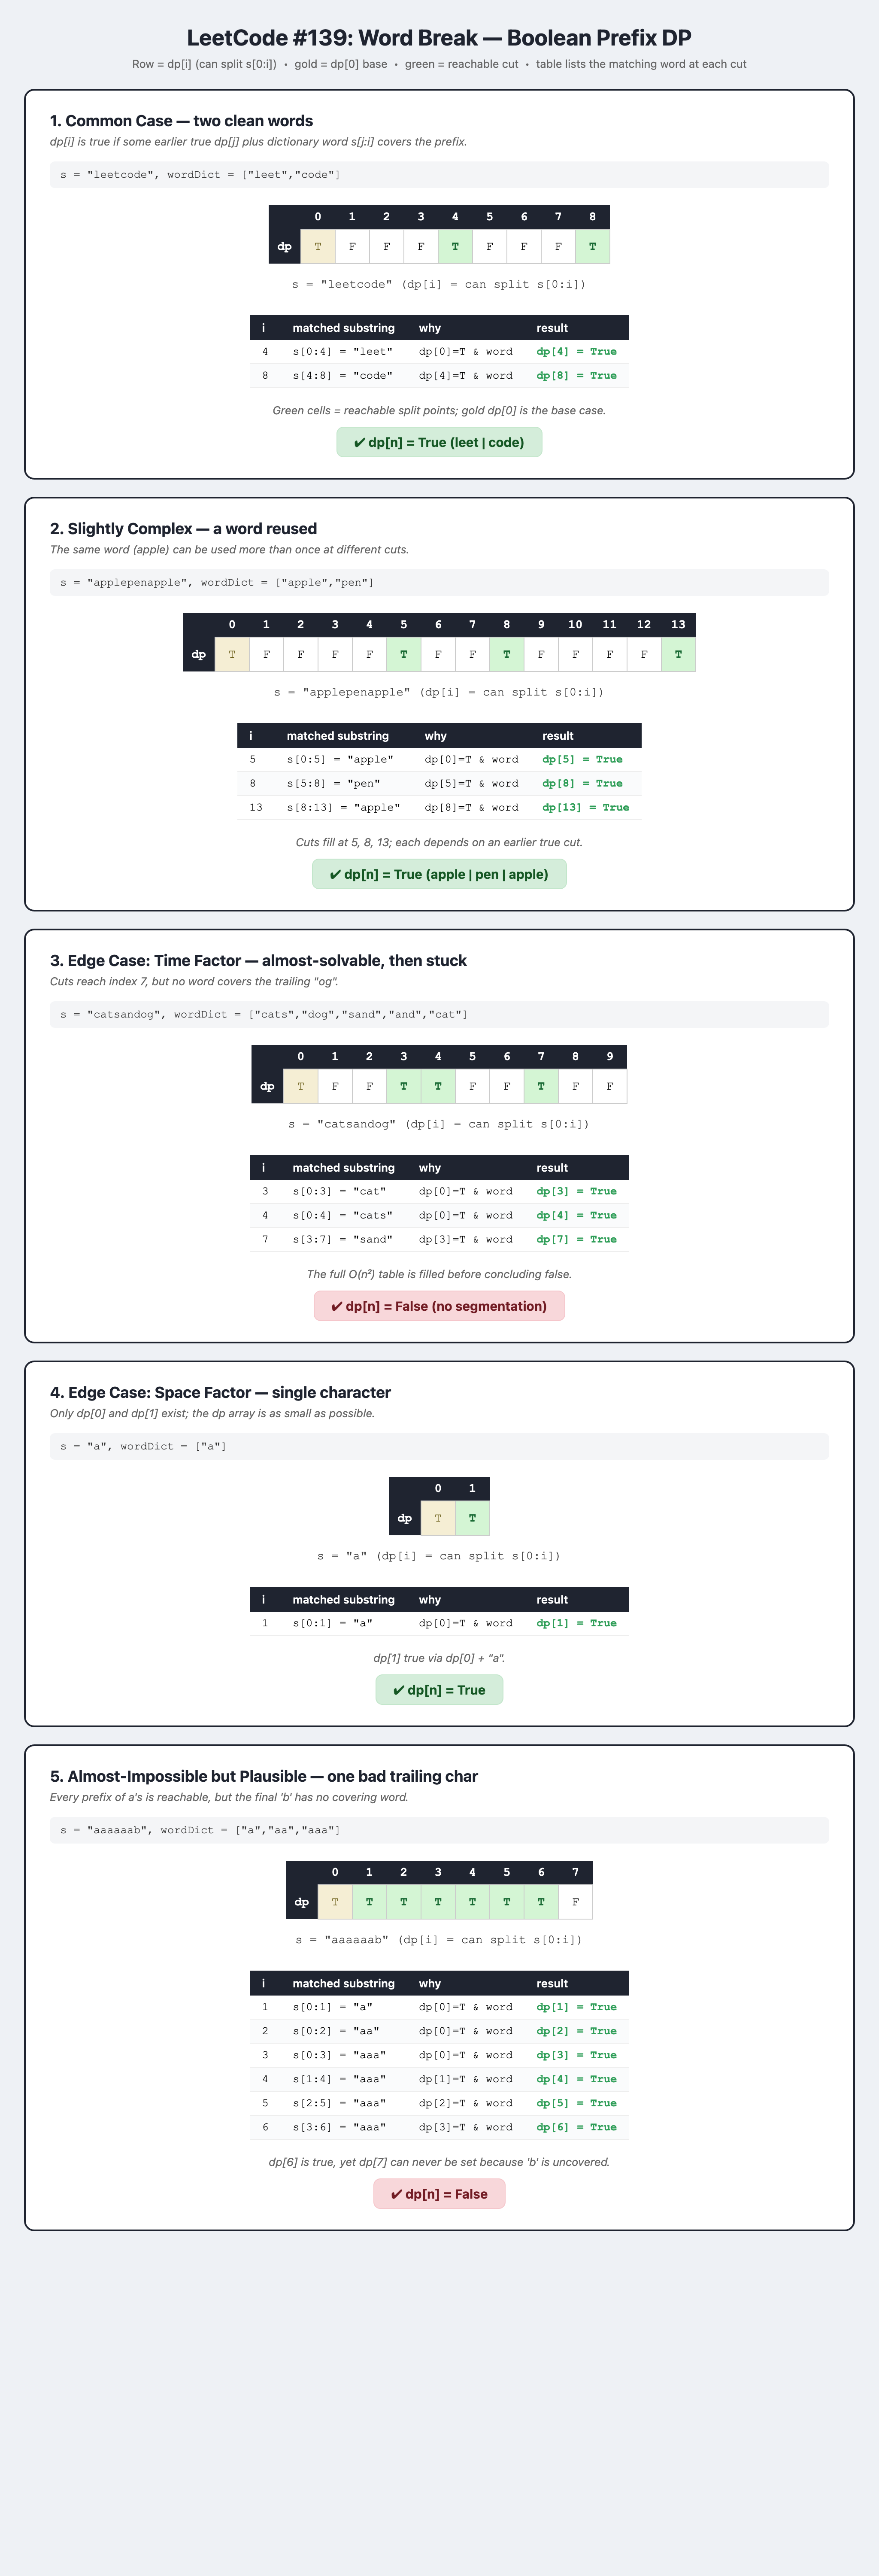